<a href="https://colab.research.google.com/github/Basty241/SteelPlateFaultsWithDatabricks/blob/main/Entrega_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#PRESENTACIÓN 1: Steel Plates Faults
Integrantes:

- Bastián Araya

- Melisa Gónzalez

#1 Introducción
*Escribe una breve descripción de en qué consiste el Data set, sus variables y cuál es el target.
(UCI Machine Learning Repository / Semeion Research Center, Buscema et al., 2010)


#2 Cargar el problema

###2.1 Importaciones

In [ ]:
# Pandas es utilizado para leer los set de datos
import pandas as pd

# Para utilizar Google Cloud y BigQuery
from google.colab import auth
from google.cloud import bigquery

# Para generar series de datos a graficar.
import numpy as np

# Para generar gráficos
from matplotlib import pyplot as plt
import seaborn as sns

# Para estadística inferencial y sets de hipótesis
import statistics as st
from scipy import stats

###2.2 Archivos

In [ ]:
# 1. Autenticar cuenta de Google en Colab
auth.authenticate_user()

# 2 Conectar con BigQuery (Melissa)
proyecto_id = "analisis-acero"
dataset_id = "dataset_acero"
table_id = "fallas_placas"
client = bigquery.Client(project=proyecto_id)

# 3 Traer toda la tabla desde BigQuery
tabla = f"{proyecto_id}.{dataset_id}.{table_id}"
infoTabla = client.get_table(tabla)

# 4 Transformar la tabla de BigQuery a un dataframe con Pandas.
consulta = f"""
    SELECT *
    FROM `{tabla}`
    """

df = client.query(consulta).to_dataframe()

###2.3 Funciones

In [ ]:
#Media, Mediana y Moda
def MMM(lista_orientacion,lista_luminosidad):
    #Medias
    media_lista_orientacion=st.mean(df['Orientation_Index'])
    media_lista_luminosidad=st.mean(df['Luminosity_Index'])
    #Medianas
    mediana_lista_orientacion=st.median(df['Orientation_Index'])
    mediana_lista_luminosidad=st.median(df['Luminosity_Index'])

    #Modas
    moda_lista_orientacion=st.mode(df['Orientation_Index'])
    moda_lista_luminosidad=st.mode(df['Luminosity_Index'])

    medidas_dispersion=pd.DataFrame([
        ['Medias',media_lista_orientacion,media_lista_luminosidad],
        ['Medianas',mediana_lista_orientacion,mediana_lista_luminosidad],
        ['Modas',moda_lista_orientacion,moda_lista_luminosidad]],
        columns=['Estadístico','Orientación','Luminosidad'])
    return print(medidas_dispersion)

#Los tres primeros cuartiles de las listas
def cuartiles(lista_orientacion,lista_luminosidad):
    cuartiles_o = st.quantiles(lista_orientacion,n=4)
    cuartiles_lum = st.quantiles(lista_luminosidad,n=4)

    tabla_cuartiles=pd.DataFrame([
        ['Q1',cuartiles_o[0],cuartiles_lum[0]],
        ['Q2',cuartiles_o[1],cuartiles_lum[1]],
        ['Q3',cuartiles_o[2],cuartiles_lum[2]]],
        columns=['Tipo de cuartil','Magnitud orientación','Magnitud luminosidad'])
    return print(tabla_cuartiles)

#Rango, Varianza, Desv estándar
def variaciones(lista_orientacion,lista_luminosidad):
    #Rangos
    rango_o = max(lista_orientacion) - (min(lista_orientacion))
    rango_lum = max(lista_luminosidad) - (min(lista_luminosidad))

    #Varianza (muestra el cuadrado de la desviación estándar, por lo que la unidad es al cuadrado)
    varianza_o=st.variance(lista_orientacion)
    varianza_lum=st.variance(lista_luminosidad)

    #Desviación estándar
    desviacion_o=st.stdev(lista_orientacion)
    desviacion_lum=st.stdev(lista_luminosidad)

    tabla_dispersion=pd.DataFrame([
        ['Rango',rango_o,rango_lum],
        ['Varianza',varianza_o,varianza_lum],
        ['Desviación estándar',desviacion_o,desviacion_lum]],
        columns=['Variable de dispersión','Magnitud orientación','Magnitud luminosidad'])
    return print(tabla_dispersion)


#Ordenar listas filtradas y tener datos de histograma
def ordenlistas(lista_orientacion,lista_luminosidad):
    orientacion_ordenada = sorted(lista_orientacion)
    luminosidad_ordenada = sorted(lista_luminosidad)
    #Quiero saber en cuánto se repite la frecuencia entre 40 intervalos equiespaciados
    #Por lo que necesito tener 80 valores para hacer la separación (así tendre 40 barras)
    intervalos_o=np.linspace(min(orientacion_ordenada),max(orientacion_ordenada),81)#80+1 porque cuenta el final del intervalo de la última barra
    intervalos_l=np.linspace(min(luminosidad_ordenada),max(luminosidad_ordenada),81)
    #Para contar las frecuencias en cada uno de los 20 intervalos
    frec_o, _ = np.histogram(orientacion_ordenada, bins=intervalos_o)
    frec_l, _ = np.histogram(luminosidad_ordenada, bins=intervalos_l)
    return frec_o, intervalos_o, frec_l, intervalos_l

config = bigquery.QueryJobConfig(maximum_bytes_billed=100_000_000)
# Ejecuta SQL en BigQuery y devuelve un DataFrame de Pandas.
def consultar(sql):
    queryToDataframe = client.query(sql, job_config=config).result().to_dataframe()
    return queryToDataframe

# Ordenar dataframe
def contarOrdenar(columna):
    conteo = df_limpio[columna].value_counts()
    conteo_ordenado = conteo.sort_index(ascending=True) # Ordena cada longitud de cinta de menor a mayor
    return conteo_ordenado

# Extraer outliers
def extraer_outliers_iqr(df_in, cols):
  filas_outliers = []
  for col in cols:
    q1 = df_in[col].quantile(0.25)
    q3 = df_in[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr

    outliersS = df_in[df_in[col]>=lim_sup]
    outliersI = df_in[df_in[col]<=lim_inf]

    outliers = pd.concat([outliersI, outliersS])
    filas_outliers.append(outliers)



  return filas_outliers


#3 Investigación de Estructura y Calidad del Dataset

##3.1 Investigación de Estructura
Vamos a utilizar métodos de pandas para obtener información sobre la estructura del dataset.

In [ ]:
# Visualizar aspectos básicos del dataset:
## Visualización de las primeras 3 líneas: ocupando .head(3)
encabezado = df.head(3)
print(encabezado, '\n')

## Visualización de las primeras 3 líneas: ocupando .head(3)
cola = df.tail(3)
print(cola, '\n')

## Tamaño del data set: ocupando .shape
filaColumna = df.shape
print(filaColumna, '\n')

## Información del tipo de datos: ocupando .info()
infoDataframe = df.info()



   X_Minimum  X_Maximum  Y_Minimum  Y_Maximum  Pixels_Areas  X_Perimeter  \
0         42         50     270900     270944           267           17   
1        645        651    2538079    2538108           108           10   
2        829        835    1553913    1553931            71            8   

   Y_Perimeter  Sum_of_Luminosity  Minimum_of_Luminosity  \
0           44              24220                     76   
1           30              11397                     84   
2           19               7972                     99   

   Maximum_of_Luminosity  ...  Orientation_Index  Luminosity_Index  \
0                    108  ...             0.8182           -0.2913   
1                    123  ...             0.7931           -0.1756   
2                    125  ...             0.6667           -0.1228   

   SigmoidOfAreas  Pastry  Z_Scratch  K_Scatch  Stains  Dirtiness  Bumps  \
0          0.5822       1          0         0       0          0      0   
1          0.2984    

Con df.info() validamos que no hay datos nulos en toda la tabla, que estamos trabajando con las variables correctas y el tipo de dato que se le asigna a cada variable.
Además, del número de filas (1941) y columnas (34) del dataset.

## 3.2 Separación de columnas
Para poder determinar correctamente el tipo de falla, separamos las variables por categoria.
- Coordenadas cartesianas: Delimitan la posición de la falla en la placa.
- Geometría: Área, proyección del perímetro en los ejes y espesor.
- Luminosidad: Intensidad lumínica en los pixeles de la falla.
- Longitud de Cinta: Variable operativa del transporte de las placas.
- Tipo de Acero: A300 o A400.
- Índices: Permiten describir la falla en relación a distintas variables, como reflectividad de la placa, proximidad a los bordes, orientación de la falla, forma, etc.
- Tipo de Falla (Target): Corresponde a la variable que queremos clasificar en función de las otras variables. Para posterior automatización de detección.

In [ ]:
# Separación de columnas para análisis.
## Extrae los nombres de las columnas.
columnas = [campo.name for campo in infoTabla.schema]

## Separamos por tipo de dato.
coordenadas = columnas[0:4]

geometria = columnas[4:7] + [columnas[13]]

luminosidad = columnas[7:10]

longitudDeCinta = columnas[10]

tipoDeAcero = columnas[11:13]

index = columnas[13:21] + columnas[24:27]

log = columnas[21:24]

tipoDeFalla = columnas[27:] # Target.

#print(index) # Casilla de verificación
#print(df[index].nunique()) # Casilla de verificación

## 3.3 Investigación de Calidad
El objetivo es determinar datos únicos, duplicados, nulos y faltantes en el dataframe.

###3.3.1 Tipo de falla (Pastry, Z_Scratch, K_Scatch, Stains, Dirtiness, Bumps, Other_Faults).

In [ ]:
# Investigación de Calidad: Tipo de falla.
## Verificación de variable categórica sin errores.
verificacion = (df[tipoDeFalla].sum(axis=1)==1).all()
print(f'¿Son las variables excluyentes?: {verificacion}')

## Frecuencias absolutas
frecuencias = df[tipoDeFalla].sum()
proporciones = frecuencias/df[tipoDeFalla].count()

## Datos únicos y duplicados
duplicados = []
nUnicos = []
for col in tipoDeFalla:
  duplicados.append(df[col].duplicated().sum())
  nUnicos.append(df[col].nunique())

## Tabla resumen
resumen = pd.DataFrame({
    'cantidad': frecuencias,
    'proporcion': proporciones,
    'porcentaje': proporciones * 100,
    'duplicados': duplicados,
    'únicos': nUnicos
    })

display(resumen.round(3))
print('\nTotal de registros:', frecuencias.sum())
print(f'Suma de proporciones: {proporciones.sum()} \n')

¿Son las variables excluyentes?: True


,cantidad,proporcion,porcentaje,duplicados,únicos
Pastry,158,0.081,8.14,1939,2
Z_Scratch,190,0.098,9.789,1939,2
K_Scatch,391,0.201,20.144,1939,2
Stains,72,0.037,3.709,1939,2
Dirtiness,55,0.028,2.834,1939,2
Bumps,402,0.207,20.711,1939,2
Other_Faults,673,0.347,34.673,1939,2



Total de registros: 1941
Suma de proporciones: 1.0 



El tipo de falla corresponde a un dato binario, por lo que es correcto que de los 1941 datos, 1939 sean duplicados, y que los 2 datos únicos sean 0 y 1.
Al no tener datos nulos se verifica que los datos de estas variables están integros y sin errores.


###3.3.2 Coordenadas, Geometría y Luminosidad
- Coordenadas(X_Minimum, X_Maximum, Y_Minimum, Y_Maximum).
- Geometría (Pixels_Areas  X_Perimeter  Y_Perimeter  Steel_Plate_Thickness).
- Luminosidad(Sum_of_Luminosity  Minimum_of_Luminosity  Maximum_of_Luminosity).

In [ ]:
# Investigación de Calidad: Coordenadas
## Datos únicos y duplicados de coordenadas.
duplicados = []
nUnicos = []
for col in coordenadas:
  duplicados.append(df[col].duplicated().sum())
  nUnicos.append(df[col].nunique())

## Tabla resumen Coordenadas.
resumen = pd.DataFrame({
    'duplicados': duplicados,
    'únicos': nUnicos
    }, index = coordenadas
                       )

display(resumen)
frecuencias = df[coordenadas].value_counts()
print(f'\nTotal de registros: {frecuencias.sum()} \n')


# Investigación de Calidad: Geometría
## Datos únicos y duplicados de Geometría.
duplicados = []
nUnicos = []
for col in geometria:
  duplicados.append(df[col].duplicated().sum())
  nUnicos.append(df[col].nunique())

## Tabla resumen Geometría.
resumen = pd.DataFrame({
    'duplicados': duplicados,
    'únicos': nUnicos
    }, index = geometria
                       )

display(resumen)
frecuencias = df[geometria].value_counts()
print(f'\nTotal de registros: {frecuencias.sum()} \n')


# Investigación de Calidad: Luminosidad
## Datos únicos y duplicados de Luminosidad.
duplicados = []
nUnicos = []
for col in luminosidad:
  duplicados.append(df[col].duplicated().sum())
  nUnicos.append(df[col].nunique())

## Tabla resumen Luminosidad.
resumen = pd.DataFrame({
    'duplicados': duplicados,
    'únicos': nUnicos
    }, index = luminosidad
    )

display(resumen)
frecuencias = df[luminosidad].value_counts()
print(f'\nTotal de registros: {frecuencias.sum()} \n')


,duplicados,únicos
X_Minimum,979,962
X_Maximum,947,994
Y_Minimum,2,1939
Y_Maximum,1,1940



Total de registros: 1941 



,duplicados,únicos
Pixels_Areas,1021,920
X_Perimeter,1542,399
Y_Perimeter,1624,317
Steel_Plate_Thickness,1917,24



Total de registros: 1941 



,duplicados,únicos
Sum_of_Luminosity,32,1909
Minimum_of_Luminosity,1780,161
Maximum_of_Luminosity,1841,100



Total de registros: 1941 



Las coordenadas, la geometría y la luminosidad corresponden a datos enteros, y como cada fila corresponde a una placa, es de esperar que no todos los datos sean únicos, ya que es el conjunto de datos lo que define una placa. Aunque como hay sólo un valor duplicado de Y_Maximum, lo más probable es que haya como mucho una fila duplicada.

In [ ]:
# Verificamos el potencial dato duplicado
potencialD = df[df[coordenadas[3]].duplicated(keep=False)]
print(f"Falla potencial: \n{potencialD}\n")


#Eliminamos la fila
df_limpio = df.drop(index=1776)

# Verificamos la corrección
print(f'Duplicados en dataframe original: {df[coordenadas[3]].duplicated().sum()}')
print(f'Duplicados en dataframe limpio: {df_limpio[coordenadas[3]].duplicated().sum()}')
df_limpio.shape

Falla potencial: 
      X_Minimum  X_Maximum  Y_Minimum  Y_Maximum  Pixels_Areas  X_Perimeter  \
1775       1002       1021      28972      28984           128           29   
1776        996       1015      28972      28984           128           29   

      Y_Perimeter  Sum_of_Luminosity  Minimum_of_Luminosity  \
1775           16              13352                     96   
1776           16              13352                     96   

      Maximum_of_Luminosity  ...  Orientation_Index  Luminosity_Index  \
1775                    116  ...            -0.3684           -0.1851   
1776                    116  ...            -0.3684           -0.1851   

      SigmoidOfAreas  Pastry  Z_Scratch  K_Scatch  Stains  Dirtiness  Bumps  \
1775          0.3787       0          0         0       0          0      0   
1776          0.3787       0          0         0       0          0      0   

      Other_Faults  
1775             1  
1776             1  

[2 rows x 34 columns]

Duplicado

(1940, 34)

No es una fila duplicada, pero es una misma falla leída 2 veces, se eliminó una vez.

Por último, al no tener datos nulos se verifica que los datos de estas variables están integros y sin errores.

### 3.3.3 Ancho de Cinta de Inspección

In [ ]:
# Investigación de Calidad: Longitud de Cinta.
## Datos únicos y duplicados de Longitud de Cinta.
duplicados = (df_limpio[longitudDeCinta].duplicated().sum())
nUnicos = (df_limpio[longitudDeCinta].nunique())

## Tabla resumen Longitud de Cinta.
resumenLC = pd.DataFrame({
    'duplicados': duplicados,
    'únicos': nUnicos
    }, index = [longitudDeCinta]
    )

display(resumenLC)
frecuencias = df_limpio[longitudDeCinta].value_counts()
print(f'\nTotal de registros: {frecuencias.sum()} \n')

,duplicados,únicos
Length_of_Conveyer,1856,84



Total de registros: 1940 



Viendo el número de datos únicos, nos damos cuenta de que existen 84 longitudes de inspección en la fábrica/planta. Esto no se relaciona en forma directa con las fallas, pero permite calcular la forma del defecto a través de los índices "Outside".

###3.3.4 Índices logarítmicos

In [ ]:
# Investigación de Calidad: .
## Datos únicos y duplicados de Longitud de Cinta.
duplicados = (df_limpio[log].duplicated().sum())
nUnicos = (df_limpio[log].nunique())

## Tabla resumen Longitud de Cinta.
resumenLC = pd.DataFrame({
    'duplicados': duplicados,
    'únicos': nUnicos
    }, index = [log]
    )

display(resumenLC)
frecuencias = df_limpio[log].value_counts()
print(f'\nTotal de registros: {frecuencias.sum()} \n')

,duplicados,únicos
LogOfAreas,60,NaN
Log_X_Index,60,NaN
Log_Y_Index,60,NaN



Total de registros: 1940 



###3.3.5 Index

In [ ]:
# Investigación de Calidad: Index
## Datos únicos y duplicados de Index.
duplicados = []
nUnicos = []
for col in index:
  duplicados.append(df_limpio[col].duplicated().sum())
  nUnicos.append(df_limpio[col].nunique())

## Evaluamos los valores máximos y mínimos de los índices, además de  los valores únicos de los OGI.
indexMax = df_limpio[index].max()
indexMin = df_limpio[index].min()

## Tabla resumen Index.
resumen = pd.DataFrame({
    'duplicados': duplicados,
    'únicos': nUnicos,
    'mínimo': indexMin,
    'máximo': indexMax
    }, index = index
                       )

display(resumen.round(3))
frecuencias = df_limpio[index].value_counts()
print(f'\nTotal de registros: {frecuencias.sum()} \n')


## Evaluamos los valores únicos de los OGI.
outsideGlobalIndex_unique = df_limpio[index[6]].unique()

## Salida
print(outsideGlobalIndex_unique)

,duplicados,únicos,mínimo,máximo
Steel_Plate_Thickness,1916,24,40.0,300.0
Edges_Index,554,1386,0.0,0.995
Empty_Index,602,1338,0.0,0.944
Square_Index,1170,770,0.008,1.0
Outside_X_Index,1486,454,0.002,0.876
Edges_X_Index,1122,818,0.014,1.0
Edges_Y_Index,1292,648,0.048,1.0
Outside_Global_Index,1937,3,0.0,1.0
Orientation_Index,1022,918,-0.991,0.992
Luminosity_Index,418,1522,-0.999,0.642



Total de registros: 1940 

[1.     0.9667 0.9474 0.9885 0.9607 0.982  0.9275 0.9559 0.9925 0.9503
 0.9605 0.9429 0.9921 0.9861 0.8571 0.986  0.9901 0.8973 0.9884 0.9412
 0.9231 0.9857 0.9903 0.9778 0.9977 0.9916 0.9821 0.8235 0.8065 0.8
 0.9826 0.9068 0.8518 0.9322 0.8929 0.9722 0.8696 0.9333 0.8095 0.5714
 0.9255 0.3796 0.9464 0.6875 0.9167 0.96   0.7041 0.9    0.9855 0.932
 0.9552 0.7979 0.9107 0.7295 0.8627 0.9394 0.9194 0.8261 0.9612 0.7455
 0.9043 0.813  0.5974 0.9623 0.97   0.875  0.5151 0.7778 0.7143 0.5429
 0.8072 0.8947 0.9048 0.8125 0.9655 0.7273 0.7576 0.8461 0.9091 0.9737
 0.5143 0.88   0.9546 0.9891 0.9024 0.6316 0.75   0.9273 0.8182 0.45
 0.6111 0.7    0.5385 0.4833 0.9524 0.6    0.52   0.9773 0.92   0.5882
 0.931  0.7059 0.9931 0.8714 0.9565 0.9535 0.8477 0.9444 0.6522 0.3559
 0.5254 0.5333 0.5417 0.963  0.9677 0.9744 0.9858 0.95   0.9615 0.9723
 0.9833 0.9808 0.7647 0.6832 0.6721 0.9796 0.9714 0.9994 0.3525 0.34
 0.3616 0.3441 0.2781 0.2863 0.3669 0.3012 0.3737 0.4249 

- Outside Global Index:
  Permite describir la forma del defecto, y toma solo 3 valores:
  - 0 (Defecto alargado en X)

  - 0.5 (Defecto sin alargamiento en un eje).

  - 1 (Defecto alargado en Y).

- Orientation_Index: Coeficiente que describe la pendiente o ángulo de orientación predominante del defecto (varía entre -1 y 1).   

- Luminosity_Index: Índice que contrasta el nivel lumínico del defecto frente a la reflectividad promedio del fondo de la placa de acero (varía entre -1 y 1).

El resto de los index, al igual que las coordenadas, geometria y luminosidad, se asumen correctas mientras no hayan valores nulos.

Los demás índices varían entre 0 y 1.

In [ ]:
dx = df_limpio['X_Maximum'] - df_limpio['X_Minimum']
dy = df_limpio['Y_Maximum'] - df_limpio['Y_Minimum']

# 1. Comprobar Outside_X_Index como razón dx / Length_of_Conveyer
error_max_x = np.abs((dx / df_limpio['Length_of_Conveyer']) - df_limpio['Outside_X_Index']).max()
print(f"Diferencia máxima en Outside_X_Index: {error_max_x:.6f}")

# 2. Comprobar Outside_Global_Index frente a la dominancia entre dy y dx
condicion = np.select([dy > dx, dy == dx, dy < dx], [1.0, 0.5, 0.0])
coincidencia = (condicion == df_limpio['Outside_Global_Index']).mean() * 100
print(f"Coincidencia exacta en Outside_Global_Index: {coincidencia:.2f}%")

Diferencia máxima en Outside_X_Index: 0.000055
Coincidencia exacta en Outside_Global_Index: 100.00%


###3.3.6 Tipo de Acero

In [ ]:
# Investigación de Calidad: Tipo de Acero.
## Verificación de variable categórica sin errores.
verificacion = (df_limpio[tipoDeAcero].sum(axis=1)==1).all()
print(f'¿Son las variables excluyentes?: {verificacion}')

## Datos únicos y duplicados de Tipo de Acero.
duplicados = []
nUnicos = []
for col in tipoDeAcero:
  duplicados.append(df_limpio[col].duplicated().sum())
  nUnicos.append(df_limpio[col].nunique())

## Tabla resumen Tipo de Acero.
resumen = pd.DataFrame({
    'duplicados': duplicados,
    'únicos': nUnicos
    }, index = tipoDeAcero
    )

display(resumen.round(3))
frecuencias = df_limpio[tipoDeAcero].value_counts()
print(f'\nTotal de registros: {frecuencias.sum()} \n')



¿Son las variables excluyentes?: True


,duplicados,únicos
TypeOfSteel_A300,1938,2
TypeOfSteel_A400,1938,2



Total de registros: 1940 



Dato categórico.

##3.4 Modificaciones

Como hay 2 sets de columnas categóricas, vamos a crear 2 columnas que las reemplacen.

In [ ]:
# Crear TypeOfSteel y limpiar el prefijo 'TypeOfSteel_'
tipoDeMetalFila = df_limpio[tipoDeAcero].idxmax(axis=1)
df_limpio['TypeOfSteel'] = (
    tipoDeMetalFila.str.replace('TypeOfSteel_', '', regex=False)
)

# Crear TypeOfFault como variable categórica objetivo
df_limpio['TypeOfFault'] = df[tipoDeFalla].idxmax(axis=1)

# Verificar resultado
print(df_limpio[['TypeOfSteel', 'TypeOfFault']].sample(10))

df_limpio.shape

     TypeOfSteel   TypeOfFault
739         A300        Stains
536         A400      K_Scatch
286         A300     Z_Scratch
339         A400     Z_Scratch
886         A400         Bumps
725         A400      K_Scatch
643         A400      K_Scatch
347         A400     Z_Scratch
1688        A400  Other_Faults
1299        A400  Other_Faults


(1940, 36)

In [ ]:
# Quitamos las filas innecesarias del dataframe "limpio".
df_limpio = df_limpio.drop(columns=tipoDeAcero + tipoDeFalla)

# Verificar resultado
print(df_limpio.sample(3))


      X_Minimum  X_Maximum  Y_Minimum  Y_Maximum  Pixels_Areas  X_Perimeter  \
1241        758        785    4758137    4758179           780           47   
248         165        176    1373431    1373442            52           17   
810        1213       1219    1962342    1962347            16            9   

      Y_Perimeter  Sum_of_Luminosity  Minimum_of_Luminosity  \
1241           45              84630                     77   
248            13               5376                     95   
810             6               2076                    123   

      Maximum_of_Luminosity  ...  Edges_Y_Index  Outside_Global_Index  \
1241                    127  ...         0.9333                   1.0   
248                     111  ...         0.8461                   0.5   
810                     141  ...         0.8333                   0.0   

      LogOfAreas  Log_X_Index  Log_Y_Index  Orientation_Index  \
1241      2.8921       1.4314       1.6233             0.3571   
248    

#4 Análisis Univariado

In [ ]:
#Has gráficos de caja para representar los outliers
#Tip 👀: En la presentación solo nombra los outliers que te llamaron la atención
#Tip 👀: Si vas a eliminar un outlier añade su respectiva justificación

##4.1 Análisis de Outliers

El análisis univariado sin condicionar arrojaría falsos outliers, por las diferencias entre tipos de falla y las diferencias de frecuencias. Por lo que este análisis no eliminará variables

In [ ]:
df_limpio.describe()

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas
count,1940.0,1940.0,1940.0,1940.0,1940.0,1940.0,1940.0,1940.0,1940.0,1940.0,...,1940.000000,1940.000000,1940.000000,1940.000000,1940.000000,1940.000000,1940.000000,1940.000000,1940.000000,1940.000000
mean,570.91701,617.759794,1651520.802577,1651574.66134,1894.78866,111.897938,83.000515,206411.611856,84.542784,130.201031,...,0.033371,0.610506,0.813505,0.576031,2.492587,1.335716,1.403438,0.083520,-0.131277,0.585527
std,520.735496,497.674001,1774653.657857,1774665.317927,5169.63653,301.28097,426.590128,512406.926254,32.141508,18.693031,...,0.058975,0.243338,0.234330,0.482299,0.789085,0.481734,0.454403,0.500892,0.148800,0.339507
min,0.0,4.0,6712.0,6724.0,2.0,2.0,1.0,250.0,0.0,37.0,...,0.001500,0.014400,0.048400,0.000000,0.301000,0.301000,0.000000,-0.991000,-0.998900,0.119000
25%,51.0,192.0,471779.5,471824.0,84.0,15.0,13.0,9519.5,63.0,124.0,...,0.006600,0.411300,0.596675,0.000000,1.924300,1.000000,1.079200,-0.324375,-0.195000,0.247875
50%,434.5,466.5,1205078.0,1205088.0,174.5,26.0,25.0,19214.0,90.0,127.0,...,0.010100,0.636400,0.947400,1.000000,2.241800,1.176100,1.322200,0.095200,-0.132900,0.506300
75%,1053.0,1072.25,2183491.25,2183501.0,822.5,84.0,83.0,83165.0,106.0,140.0,...,0.023525,0.800000,1.000000,1.000000,2.915150,1.518500,1.732400,0.512025,-0.066575,0.999800
max,1705.0,1713.0,12987661.0,12987692.0,152655.0,10449.0,18152.0,11591414.0,203.0,253.0,...,0.875900,1.000000,1.000000,1.000000,5.183700,3.074100,4.258700,0.991700,0.642100,1.000000


###4.1.1 Outliers por Coordenadas

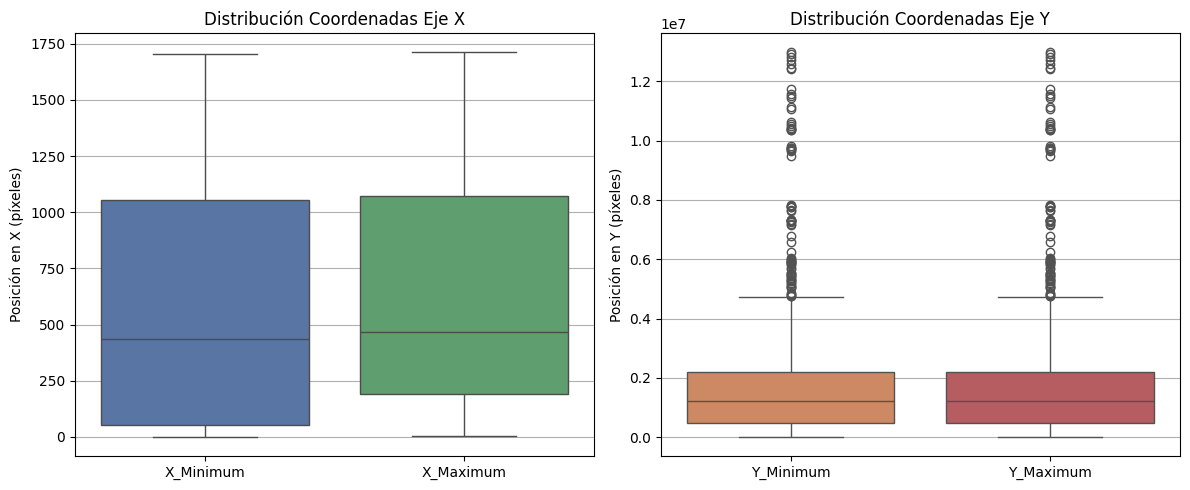

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Panel 1: Solo coordenadas en X.
sns.boxplot(data=df_limpio[coordenadas[0:2]], ax=axes[0], palette=['#4C72B0', '#55A868'])
axes[0].set_title('Distribución Coordenadas Eje X')
axes[0].set_ylabel('Posición en X (píxeles)')

# Panel 2: Solo coordenadas en Y.
sns.boxplot(data=df_limpio[coordenadas[2:4]], ax=axes[1], palette=['#DD8452', '#C44E52'])
axes[1].set_title('Distribución Coordenadas Eje Y')
axes[1].set_ylabel('Posición en Y (píxeles)')

# Añadir gradillas horizontales.
axes[0].grid(axis='y')
axes[0].set_axisbelow(True)#Líneas horizontales grises que marcan el eje x

axes[1].grid(axis='y')
axes[1].set_axisbelow(True)#Líneas horizontales grises que marcan el eje x

# Graficar
plt.tight_layout()
plt.show()

En el eje X no hay outliers, pero en el eje Y hay muchos outliers con una dispersión importante. Esto se debe porque estas coordenadas corresponden al marco de lectura de las placas en continuo, entonces como se trata de una linea procesadora, un marco de lectura puede haber tomado miles de placas.

Por lo que no se eliminará ningún outlier de estas mediciones

###4.1.2 Outliers (atípico) de Forma

/tmp/ipykernel_1161/2086018052.py:8: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.boxplot(data=df_limpio[geometria[1:2]], ax=axes[1], palette=['#55A868', '#189ad3'])


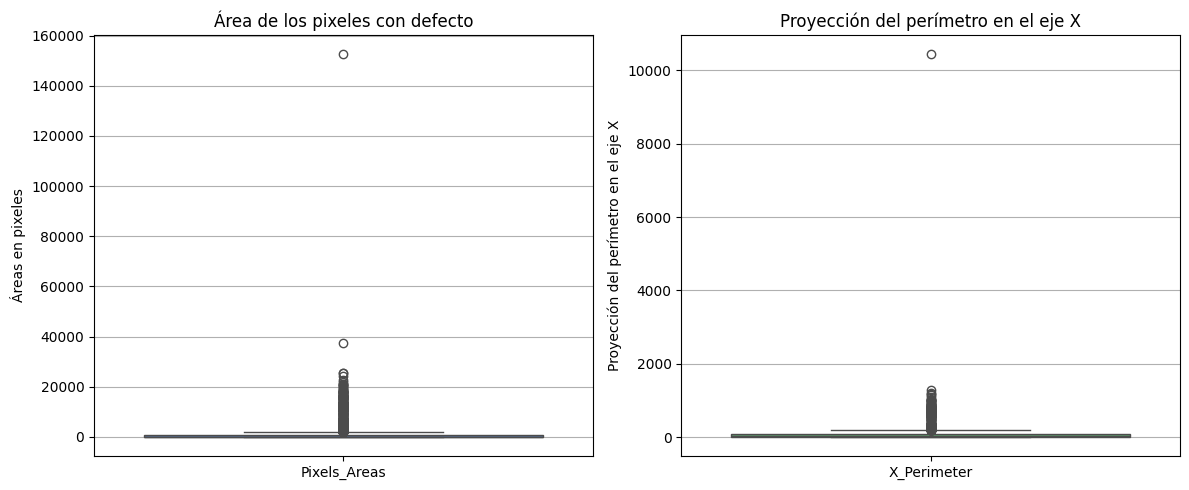

In [184]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Panel 1: Áreas en pixeles.
sns.boxplot(data=df_limpio[geometria[0:1]], ax=axes[0], palette=['#4C72B0'])
axes[0].set_title('Área de los pixeles con defecto')
axes[0].set_ylabel('Áreas en pixeles')

# Panel 2: Proyección del perímetro de la figura en el eje X.
sns.boxplot(data=df_limpio[geometria[1:2]], ax=axes[1], palette=['#55A868', '#189ad3'])
axes[1].set_title('Proyección del perímetro en el eje X')
axes[1].set_ylabel('Proyección del perímetro en el eje X')

# Añadir gradillas horizontales.
axes[0].grid(axis='y')
axes[0].set_axisbelow(True)

axes[1].grid(axis='y')
axes[1].set_axisbelow(True)

# Graficar
plt.tight_layout()
plt.show()

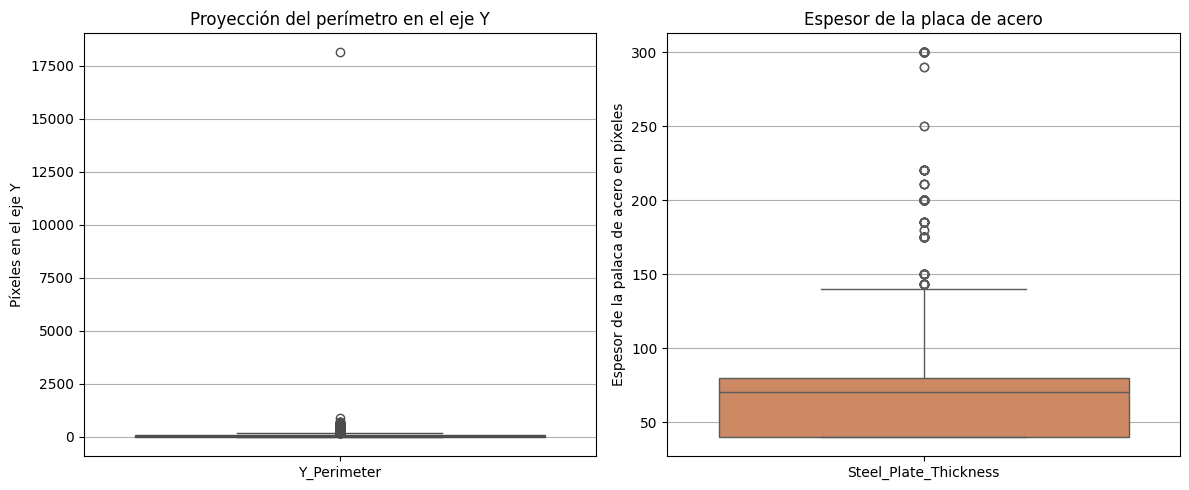

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Panel 1: Proyección del perímetro de la figura en el eje Y.
sns.boxplot(data=df_limpio[geometria[2:3]], ax=axes[0], palette=['#4C72B0'])
axes[0].set_title('Proyección del perímetro en el eje Y')
axes[0].set_ylabel('Píxeles en el eje Y')

# Panel 2: Espesor de la placa de acero.
sns.boxplot(data=df_limpio[geometria[3:4]], ax=axes[1], palette=['#DD8452'])
axes[1].set_title('Espesor de la placa de acero')
axes[1].set_ylabel('Espesor de la palaca de acero en píxeles')

# Añadir gradillas horizontales.
axes[0].grid(axis='y')
axes[0].set_axisbelow(True)

axes[1].grid(axis='y')
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.show()

In [177]:
# Extraemos los outliers según coordenadas para análisis
df_out = extraer_outliers_iqr(df_limpio, geometria)

# Evaluamos primero los outliers de los ejes que más llaman la atención.
print(f'Outliers de Pixels_Areas \n{df_out[0][df_out[0]['Pixels_Areas'] > 40000].index}\n')
print(f'Outliers de X_Perimeter \n{df_out[1][df_out[1]['X_Perimeter'] > 2000].index}\n')
print(f'Outliers de Y_Perimeter \n{df_out[2][df_out[2]['Y_Perimeter'] > 2500].index}\n')

# Revisamos el outlier
display(df.loc[[391]])

Outliers de Pixels_Areas 
Index([391], dtype='int64')

Outliers de X_Perimeter 
Index([391], dtype='int64')

Outliers de Y_Perimeter 
Index([391], dtype='int64')



,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
391,19,169,4197607,4215748,152655,10449,18152,11591414,0,156,...,0.9917,-0.4068,1.0,0,0,1,0,0,0,0


Los outliers evaluados corresponden a un mismo dato (391), asumiendo 0,5mm por pixel, la falla tendría una proyección de 5,22m en el eje x y 9,07m en el eje y. De ser 0,1mm por pixel sería de 1,04m x 1,82m. De todas formas se trata de una falla de gran complejidad ya que es 70 veces la longitud del borde en el eje x, en el eje y es sólo una vez, lo que significa que el marco de lectura no encierra la falla en su totalidad. Además su empty index es de 0,9439, lo que indica que la falla ocupa poco espacio.

In [149]:
# Evaluamos los outiers del espesor de las placas de acero sobre 150px y sobre 300px.
print(f'Outliers de Steel_Plate_Thickness > 150 \n{df_out[3][df_out[3]['Steel_Plate_Thickness'] >= 150].shape}\n')
print(f'Outliers de Steel_Plate_Thickness > 300 \n{df_out[3][df_out[3]['Steel_Plate_Thickness'] >= 300].shape}\n')

Outliers de Steel_Plate_Thickness > 150 
(222, 27)

Outliers de Steel_Plate_Thickness > 300 
(43, 27)



Como se tienen 222 datos sobre el límite superior, borrarlos implicaría perder muchos datos. Por lo que por falta de información sobre los objetivos de producción, no podemos determinar si estos datos atípicos son errores.

Además, se debe estudiar la relación entre el grosor del acero y el tipo de falla.

###4.1.3 Outliers Luminosidad

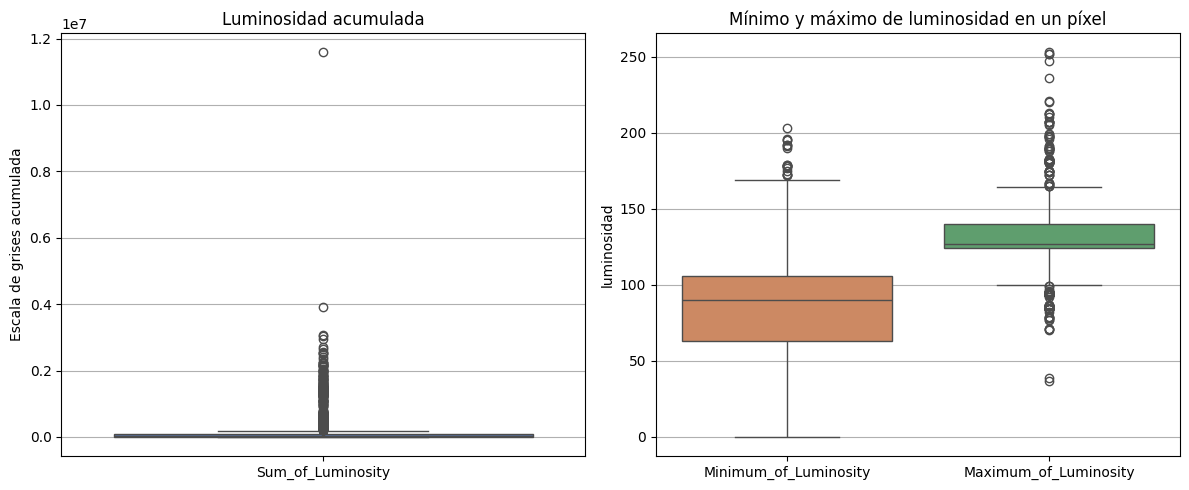

In [189]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Panel 1: Suma de Luminosidad.
sns.boxplot(data=df_limpio[luminosidad[0:1]], ax=axes[0], palette=['#4C72B0'])
axes[0].set_title('Luminosidad acumulada')
axes[0].set_ylabel('Escala de grises acumulada')

# Panel 2: Espesor de la placa de acero.
sns.boxplot(data=df_limpio[luminosidad[1:]], ax=axes[1], palette=['#DD8452', '#55A868'])
axes[1].set_title('Mínimo y máximo de luminosidad en un píxel')
axes[1].set_ylabel('luminosidad')

# Añadir gradillas horizontales.
axes[0].grid(axis='y')
axes[0].set_axisbelow(True)

axes[1].grid(axis='y')
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.show()

La luminosidad se encuentra en escala de grises

### 4.1.4 Outliers Logarítmicos

Por otro lado los logaritmos entregan información del cuadro delimitador de ancho ∆x y largo ∆y que envuelve la falla detectada. Outliers aquí indicarían fallas de tamaños poco comunes en uno de los ejes de coordenadas.

/tmp/ipykernel_1161/11121039.py:3: UserWarning: 
The palette list has fewer values (2) than needed (3) and will cycle, which may produce an uninterpretable plot.
  sns.boxplot(data=df_limpio[log], ax=ax, palette=['#55A868', '#DD8452'])


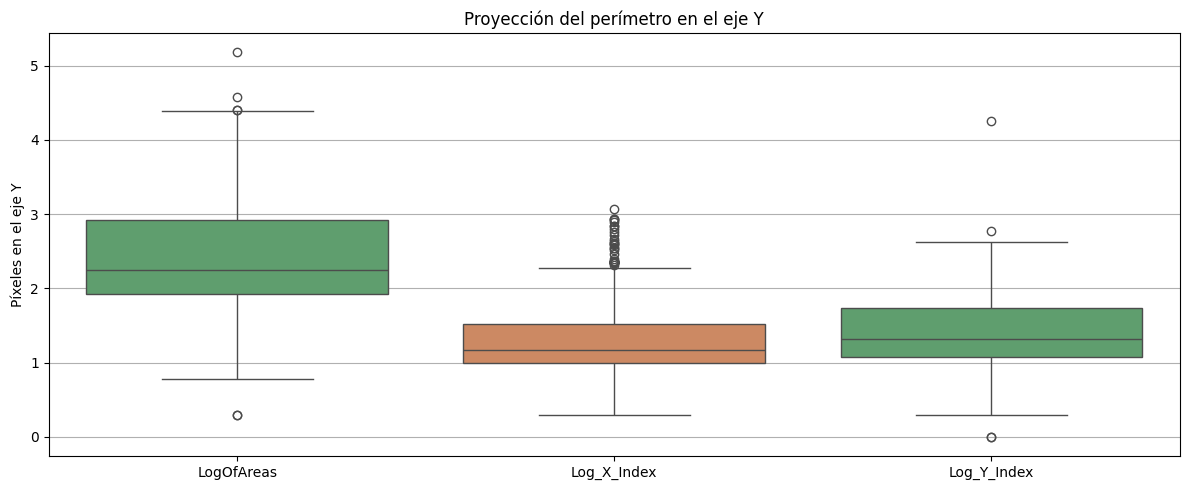

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))
# Solo coordenadas en X (coordenadas[0:2])
sns.boxplot(data=df_limpio[log], ax=ax, palette=['#55A868', '#DD8452'])
ax.set_title('Proyección del perímetro en el eje Y')
ax.set_ylabel('Píxeles en el eje Y')

# Añadir rejillas horizontales
ax.grid(axis='y')
ax.set_axisbelow(True)

# Graficar
plt.tight_layout()
plt.show()

Los outliers de Log_Y_Index preocupan más, porque 2 de ellos son de 1 pixel de altura, mientras que otra es de 20000 pixeles, lo que vendría siendo como 20m. Estos outliers por su magnitud serán descartados.

Los outliers de Log_X_Index corresponden en su mayoría a K_scatch u Other_Faults, por lo que no se trata de un error como tal sino a la naturaleza de la falla. Aunque hay un único dato que corresponde a bump, lo cual de seguro se trata de un error, ya que este tipo de falla es puntual y no se propaga.

In [ ]:
df_out = extraer_outliers_iqr(df_limpio, geometria)

In [154]:
# Extraemos los outliers según coordenadas para análisis
df_out = extraer_outliers_iqr(df_limpio, log)

# Evaluamos los outliers de los logaritmos de las áreas.
print(f'Outliers de LogOfAreas \n{df_out[0].index}\n')
print(f'Outliers de Log_X_Index \n{df_out[1].index}\n')
print(f'Outliers de Log_Y_Index \n{df_out[2].index}\n')

# Evaluamos el valor máximo de Logs
maxLogA = df_limpio['LogOfAreas'].idxmax()
print(f'Valor máximo de LogOfAreas: {maxLogA}\n')

maxLogX = df_limpio['Log_X_Index'].idxmax()
print(f'Valor máximo de Log_X_Index: {maxLogX}\n')

maxLogY = df_limpio['Log_Y_Index'].idxmax()
print(f'Valor máximo de Log_Y_Index: {maxLogY}\n')

# Evaluamos el valor mínimo de Log_Y y de LogOfAreas
minLogY = df_limpio['Log_Y_Index'].idxmin()
print(f'Valor mínimo de Log_Y_Index: {minLogY}\n')

minLogA = df_limpio['LogOfAreas'].idxmin()
print(f'Valor mínimo de LogOfAreas: {minLogA}\n')


Outliers de LogOfAreas 
Index([391, 392, 394, 1592, 621, 654], dtype='int64')

Outliers de Log_X_Index 
Index([ 392,  393,  394,  395,  396,  397,  398,  399,  400,  403,  405,  407,
        408,  418,  441,  491,  723,  724,  725,  726,  727, 1098, 1352, 1363,
       1375, 1376, 1377, 1379, 1381, 1382, 1383, 1390, 1668, 1863],
      dtype='int64')

Outliers de Log_Y_Index 
Index([83, 391, 621, 654], dtype='int64')

Valor máximo de LogOfAreas: 391

Valor máximo de Log_X_Index: 1382

Valor máximo de Log_Y_Index: 391

Valor mínimo de Log_Y_Index: 621

Valor mínimo de LogOfAreas: 621



In [183]:
# Auditar la fila 621, el dato de 2px x 1px.
display(df_limpio.loc[[621]])

# Auditar la fila 1098, el dato de mayor longitud horizontal que corresponde a un bump/bulto.
display(df_limpio.loc[[1098]])

# Auditar la fila 391, el dato de mayor longitud vertical.
display(df_limpio.loc[[391]])


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,TypeOfSteel,TypeOfFault
621,190,192,1729556,1729557,2,2,1,255,126,133,...,1.0,0.0,0.301,0.301,0.0,-0.5,-0.0039,0.119,A400,K_Scatch



Para el índice 621 - Hay 0 vecinos cercanos en Y



,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,TypeOfSteel,TypeOfFault
1098,787,1316,3544454,3544490,8391,609,343,991612,103,140,...,0.105,0.0,3.9238,2.7235,1.5563,-0.9319,-0.0768,1.0,A400,Bumps


,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,...,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,TypeOfSteel,TypeOfFault
391,19,169,4197607,4215748,152655,10449,18152,11591414,0,156,...,0.9994,1.0,5.1837,2.1761,4.2587,0.9917,-0.4068,1.0,A400,K_Scatch


###4.1.5 Outliers Índices

/tmp/ipykernel_1161/1667222780.py:3: UserWarning: The palette list has more values (3) than needed (1), which may not be intended.
  sns.boxplot(data=df_limpio[index[0:1]], ax=axes[0], palette=['#4C72B0', '#55A868','#DD8452'])


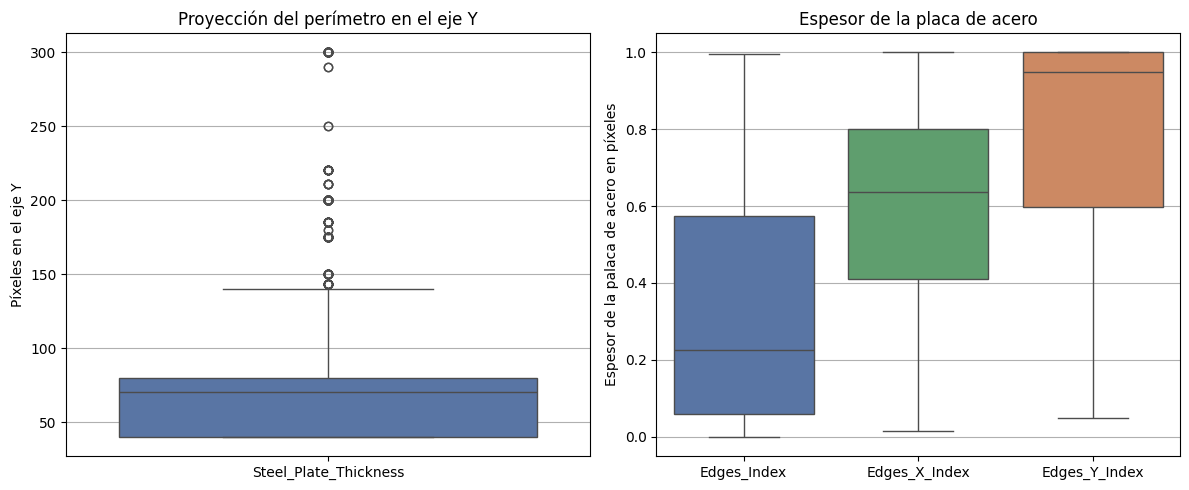

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Panel 1: Solo coordenadas en X (coordenadas[0:2])
sns.boxplot(data=df_limpio[index[0:1]], ax=axes[0], palette=['#4C72B0'])
axes[0].set_title('Proyección del perímetro en el eje Y')
axes[0].set_ylabel('Píxeles en el eje Y')

# Panel 2: Solo coordenadas en Y (coordenadas[2:4])
sns.boxplot(data=df_limpio[[index[1]]+index[5:7]], ax=axes[1], palette=['#4C72B0', '#55A868','#DD8452'])
axes[1].set_title('Espesor de la placa de acero')
axes[1].set_ylabel('Espesor de la palaca de acero en píxeles')

# Add horizontal grid
axes[0].grid(axis='y')
axes[0].set_axisbelow(True)

axes[1].grid(axis='y')
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1161/3910145568.py:8: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.boxplot(data=df_limpio[[index[7],index[10]]], ax=axes[1], palette=['#4C72B0', '#55A868','#DD8452'])


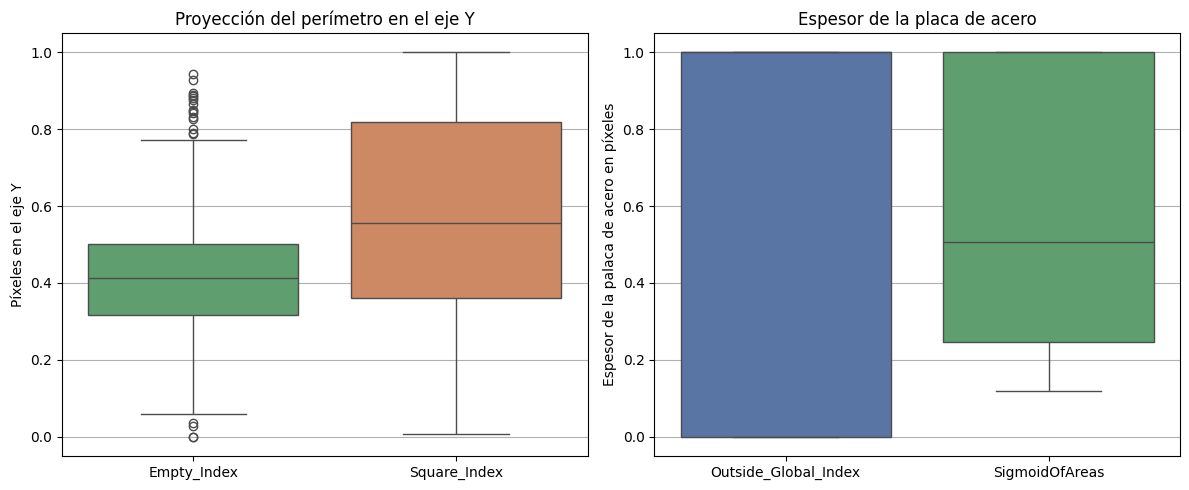

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
# Panel 1: Solo coordenadas en X (coordenadas[0:2])
sns.boxplot(data=df_limpio[index[2:4]], ax=axes[0], palette=['#55A868', '#DD8452'])
axes[0].set_title('Proyección del perímetro en el eje Y')
axes[0].set_ylabel('Píxeles en el eje Y')

# Panel 2: Solo coordenadas en Y (coordenadas[2:4])
sns.boxplot(data=df_limpio[[index[7],index[10]]], ax=axes[1], palette=['#4C72B0', '#55A868','#DD8452'])
axes[1].set_title('Espesor de la placa de acero')
axes[1].set_ylabel('Espesor de la palaca de acero en píxeles')

# Add horizontal grid
axes[0].grid(axis='y')
axes[0].set_axisbelow(True)

axes[1].grid(axis='y')
axes[1].set_axisbelow(True)

plt.tight_layout()
plt.show()

Son demasiados valores para ser realmente todos outliers.

In [ ]:
fig, ax = plt.subplots(figsize=(6, 5))
# Panel 1: Solo coordenadas en X (coordenadas[0:2])
sns.boxplot(data=df_limpio[index[10:12]], ax=ax, palette=['#4C72B0'])
ax.set_title('Proyección del perímetro en el eje Y')
ax.set_ylabel('Píxeles en el eje Y')

# Add horizontal grid
ax.grid(axis='y')
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

##4.2 Análisis Gráfico / Distribución de Fallas

In [ ]:
#Tip 👀: Te recomiendo hacer gráficos para ver tu variable claramente (Histográma, gráfico de barras, gráfico de dispersión, etc.)
#Tip 👀: Recuerda poner los ejes de los gráficos
#Si tienes columnas cualitativas ocupa One Hot Encoder !!

###4.2.1 Distribución según tipo de falla
Queremos visualizar en forma prematura, qué tipo de falla tiene mayor incidencia.

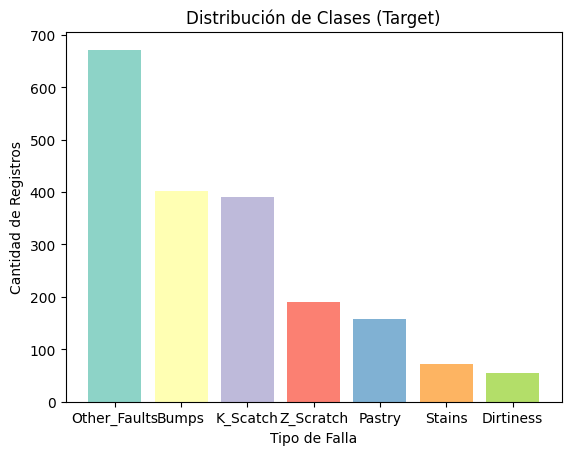

In [ ]:
## Conteo de fallas por tipo de falla.
conteo_fallas = df_limpio['TypeOfFault'].value_counts()

## Definir ejes de la gráfica
barras = conteo_fallas.index
altura = conteo_fallas.values

## Mapa de color y numeración de barras para asignación
cMap1 = plt.get_cmap("Set3")
x_ax = np.arange(len(barras))

## Gráfica de número de fallas por tipo de falla
plt.bar(barras, altura, align="center", color = cMap1(x_ax))
plt.title("Distribución de Clases (Target)")
plt.xlabel("Tipo de Falla");
plt.ylabel("Cantidad de Registros");


En orden, las fallas más comunes son K_Scatch, Bumps y Z_Scratch.

Other Faults corresponde a un cúmulo de fallas no explícitamente clasificadas, por lo que no podemos indicar si corresponde a una falla puntual con mayor incidencia que las otras.

###4.2.2 Longitud de Cinta
Queremos visualizar qué longitud de cinta produce más fallas.

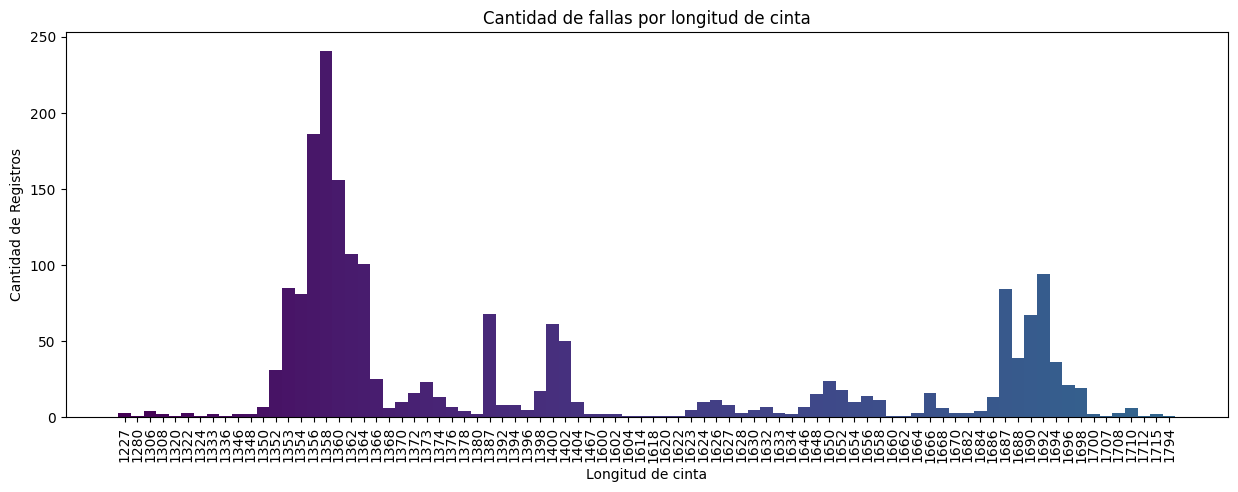

In [ ]:
## Conteo y ordenar duplicados por dato único
longOrdenada = contarOrdenar(longitudDeCinta)

## Definir ejes de la gráfica
barras = longOrdenada.index
altura = longOrdenada.values

## Mapa de color y numeración de barras para asignación
cMap2 = plt.get_cmap("viridis")
x_ax = np.arange(len(barras))

## Gráfica de número de fallas por tipo de falla
plt.figure(figsize=(15, 5))
plt.bar(x_ax, altura, color = cMap2(x_ax), width=1)
plt.title("Cantidad de fallas por longitud de cinta")
plt.xticks(x_ax, barras, rotation=90)
plt.xlabel("Longitud de cinta");
plt.ylabel("Cantidad de Registros");

En base a la distribución de fallas, sabemos que los registros corresponden principalmente a las cintas entre 1352-1366, 1387, 1400, 1402 y 1686-1698.
Como no tenemos información sobre la operación sin fallas, no podemos concluir nada a partir de estos datos por si solos. Ya que, si todas las máquinas procesan el mismo número de placas en un período de tiempo t, entonces se recomendaría no utilizar las cintas con más fallas.

Pero, existe la posibilidad de que los registros de longitudes de cinta distintas a las mencionadas, correspondan a cintas que se utilizan menos. De ser este el caso, se debieran despreciar los longitudes menos utilizadas.

Además, el único motivo para la incorporación de este dato, es para calcular los "Outside Index", con el fin de describir la forma.

Por ende, por falta de claridad y sentido físico, se despreciará este dato para el análisis.

###4.2.3 Índice de Alargamiento (Outside Global Index)

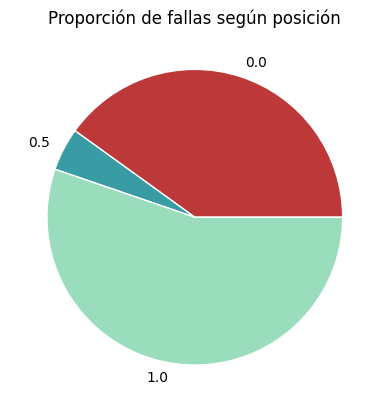

In [ ]:
## Conteo y orden de duplicados por dato único de Outside Global Index (OGI)
OGI = contarOrdenar(index[7])

## Definir ejes de la gráfica
cortes = OGI.index
tamaño = OGI.values

## Colores
colores = ["#bd3939",	"#399ba3", "#9addbd"]

## Gráfica de número de fallas por tipo de falla
plt.pie(tamaño, labels=cortes, colors=colores, wedgeprops = { 'linewidth' : 1, 'edgecolor' : 'white' });
plt.title("Proporción de fallas según posición");

En su mayoría las fallas presentan un alargamiento en un eje.

Esto se debe a la sensibilidad de este índice, para que OGI sea 0.5, Outside_X_index y Outside_Y_Index deben ser idénticos o prácticamente idénticos según la configuración de tolerancia.

### 4.2.4 Tipo de Acero

In [ ]:
## Conteo de fallas por tipo de Acero.
conteoAcero = df_limpio[tipoDeAcero].value_counts()

## Definir ejes de la gráfica
aceros = conteoAcero.index
cantidad = conteoAcero.values

## Colores
colores = ["#bd3939",	"#399ba3"]

## Gráfica de número de fallas por tipo de falla
plt.pie(cantidad, labels=aceros, colors=colores, wedgeprops = { 'linewidth' : 1, 'edgecolor' : 'white' });
plt.title("Proporción de fallas según tipo de acero");

Se tiene que 1164 datos corresponde a A400, y 777 corresponden a A300. La diferencia no es lo suficientemente significativa como para descargar ninguno, se debe relacionar con tipo de falla.

##4.4 Estadística Descriptiva

In [ ]:
# ocupando .describe()

#5 Análisis Bivariado

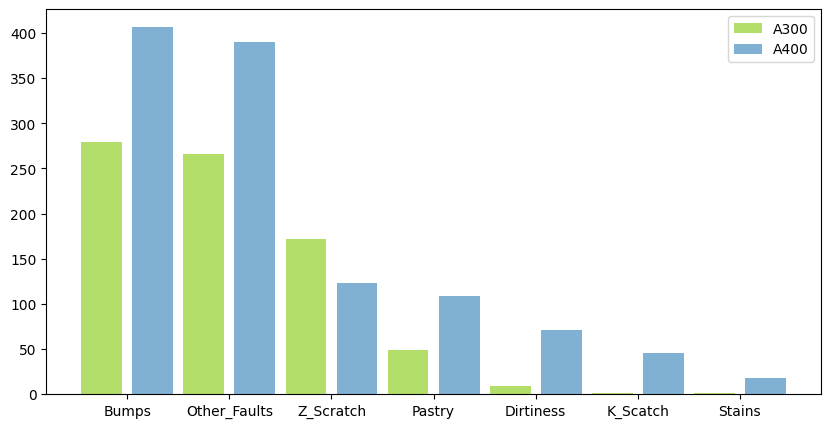

In [175]:
# Posición de cada tipo de falla
df_a300 = df_limpio[df_limpio['TypeOfSteel']=='A300']
conteoFallas_a300 = df_a300['TypeOfFault'].value_counts()

df_a400 = df_limpio[df_limpio['TypeOfSteel']=='A400']
conteoFallas_a400 = df_a400['TypeOfFault'].value_counts()

# Definir posición de las barras en la gráfica
r1 = [1,3,5,7,9,11,13]
r2 = [2,4,6,8,10,12,14]
r3 = r1 + r2

# Definir altura de las barras en la gráfica
altura1 = conteoFallas_a300.values
altura2 = conteoFallas_a400.values
altura = altura1 + altura2

# Definir barras
barras1 = conteoFallas_a300.index
barras2 = conteoFallas_a400.index

# Mapa de color y numeración de barras para asignación
cMap1 = plt.get_cmap("Set3")
x_ax = np.arange(len(r3))
barWidth = 0.8

# Crear gráfico de barras
plt.figure(figsize=(10, 5))
plt.bar(r1, altura1, width = barWidth, color = cMap1(6), label='A300')
plt.bar(r2, altura2, width = barWidth, color = cMap1(4), label='A400')

# Leyendas
plt.legend()

# Nombre de las variables en el eje X
plt.xticks([r + barWidth - 0.3 for r in r1], barras1);

In [ ]:
# Posición de cada tipo de falla
df_OGI_1 = df[df['Outside_Global_Index'] == 1]
conteoFallas_OGI_1 = df_OGI_1[tipoDeFalla].sum()

df_OGI_2 = df[df['Outside_Global_Index'] == 0.5]
conteoFallas_OGI_2 = df_OGI_2[tipoDeFalla].sum()

df_OGI_3 = df[df['Outside_Global_Index'] == 0]
conteoFallas_OGI_3 = df_OGI_3[tipoDeFalla].sum()

# Definir posición de las barras en la gráfica
r1 = [1,4,7,10,13,16,19]
r2 = [2,5,8,11,14,17,20]
r3 = [3,6,9,12,15,18,21]
r4 = r1 + r2 + r3

# Definir altura de las barras en la gráfica
altura1 = conteoFallas_OGI_1.values
altura2 = conteoFallas_OGI_2.values
altura3 = conteoFallas_OGI_3.values
altura = altura1 + altura2 + altura3

# Definir barras
barras1 = conteoFallas_OGI_1.index
barras2 = conteoFallas_OGI_2.index
barras3 = conteoFallas_OGI_3.index

# Mapa de color y numeración de barras para asignación
cMap1 = plt.get_cmap("Set3")
x_ax = np.arange(len(r4))
barWidth = 0.8

# Crear gráfico de barras
plt.figure(figsize=(10, 5))
plt.bar(r1, altura1, width = barWidth, color = cMap1(6), label='Vertical')
plt.bar(r2, altura2, width = barWidth, color = cMap1(4), label='Sin alargamiento')
plt.bar(r3, altura3, width = barWidth, color = cMap1(3), label='Horizontal')

# Leyendas
plt.legend()

# Nombre de las variables en el eje X
plt.xticks([r + barWidth + 0.15 for r in r1], barras1);

#6 Análisis Multivariado

In [ ]:
# Acá son sólo las columnas que se trabajarán en la de independiente

columnas_que_quiero_ver=["K_Scatch", "Z_Scratch","TypeOfSteel_A300","Orientation_Index","Luminosity_Index"]

print(df[columnas_que_quiero_ver].head)

#Esto es para trabajar de forma más simple los valores
lista_K_S=df['K_Scatch'].tolist()
lista_Z_S=df['Z_Scratch'].tolist()
lista_acero=df['TypeOfSteel_A300'].tolist()
lista_orientacion=df['Orientation_Index'].tolist()
lista_luminosidad=df['Luminosity_Index'].tolist()

#Entonces acá se usa Z-S
#Igualmente se puede hacer con test de fisher pero quizás es mejor así con código nomás ? queda como pregunta.

##Paso 1) Problema: Un ingeniero quiere saber qué características son las más comunes entre dos fallas que ocurren en probetas de acero A300,ArithmeticError así para
#analizar qué tan crónico es y qué tratamiento se puede hacer. Para eso, se toman otras 2 características de las probetas con fallos:
# Orientación de la falla (-1 a 1), Iluminación de la falla (-1 a 1).


##Paso 2) Observar tamaño de cada grupo; medias y dispersión. Además ver el diagrama de cajas.

#Contar
#quería comprobar longitudes
print('Hay ',len(lista_K_S), len(lista_Z_S), len(lista_acero), len(lista_orientacion), len(lista_luminosidad), 'para K-S, Z-S, Acero, Orientación y luminosidad respectivamente.')
print('Son ', len(lista_acero) , ' valores en la lista y de ellos, ', lista_acero.count(1), ' son Acero A300.')

#Ver de cuántos K-S y Z-S son de A300
ite1 = 0
for i, j in zip(lista_K_S, lista_acero):
    if i == 1 and j == 1:
        ite1 = ite1 + 1

ite2 = 0
for i, j in zip(lista_Z_S, lista_acero):
    if i == 1 and j == 1:
        ite2 = ite2 + 1

print('Cuántas fallas de K-S son probetas de A300:', ite1)
print('Cuántas fallas de Z-S son probetas de A300:', ite2)

#Acá limpiaré los datos, la variable independiente que no sea acero A300 la eliminaré de la lista
#Por lo que recorro la lista de A300 y de forma paralela, recorro la de orientación y luminosidad,
#los que no sean A300=1 se van borrando. Quedarán listas modificadas

iteracion=0
lis1=[]
lis2=[]
for i in lista_acero:
    if len(lista_orientacion)==iteracion:
        break
    if i==1:
        lis1.append(lista_orientacion[iteracion])
        lis2.append(lista_luminosidad[iteracion])
        iteracion=iteracion+1
lista_orientacion=lis1
lista_luminosidad=lis2
print(len(lista_orientacion),' ',len(lista_luminosidad))

#Voy a calcular las medidas de dispersión de datos continuos con funciones
MMM(lista_orientacion,lista_luminosidad)

#Función de Cuartiles
cuartiles(lista_orientacion,lista_luminosidad)

#Función de variables de dispersión
variaciones(lista_orientacion,lista_luminosidad)

#Diagrama de caja o Diagrama de bigotes
plt.boxplot([lista_orientacion, lista_luminosidad], tick_labels=['Orientación', 'Luminosidad'])
plt.title('Diagrama de caja')
plt.ylabel('Valor del índice')
plt.show()

#Llamo a funciones que ordenan de menor a myor las listas y hacen histogramas por intervalos
frecuencia_orientacion,intervalos_orientacion,frecuencia_luminosidad,intervalos_luminosidad=ordenlistas(lista_orientacion,lista_luminosidad)

plt.hist(lista_orientacion, bins=intervalos_orientacion,color='blue', edgecolor='black')
plt.title('Histograma de la característica de Orientación')
plt.xlabel('20 Intervalos')
plt.ylabel('Frecuencian por intervalos')
plt.show()

plt.hist(lista_luminosidad, bins=intervalos_luminosidad, color='orange', edgecolor='black')
plt.title('Histograma de la característica de Luminosidad')
plt.xlabel('20 Intervalos')
plt.ylabel('Frecuencian por intervalos')
plt.show()

#7 Estadística Inferencial Test de hipótesis

Paso 3) Hacer las afirmaciones para las hipótesis nulas y alternativas.
Proporción de fallas en Z-S en acero A300 es mayor que la proporción de fallos K-S en acero A300 (esta no sé si es necesaria hacerse porque ya se vió que hay mayores Z-S sólo contandolos al incio)
En las fallas de Z-S hay mayor defectos verticales (Orientación > 0) que horizontales (Orientación < 0).
En las fallas de Z-S con defectos verticales (orientación > 0) es mayor a las fallas de Z-S con características de Luminosidad < 0
Las fallas de Z-S con defectos verticales (orientación > 0) tienen un comportamiento normal
Las fallas de Z-S con características de Luminosidad < 0 tienen un comportamiento normal (agregué esta)
Entonces, los tests de hipótesis serían:

H0= ; H1=
Elemento de lista
Elemento de lista
Elemento de lista
Elemento de lista

###7.1 Test ______

#8 Conclusión

#9 Referencias